# Stochastic Input in the Leaky Integrate-and-Fire Neuron

## 1. Introduction

In this notebook i study the response of a Leaky Integrate and Fire neuron (LIF) to both deterministic and stochastic inputs. Firstly, i validate the basic neuron model, then compare Gaussian noisy current with a Poisson generated synaptic input. Finaly, i also introduce excitatory and inhibatory population

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 2. Leaky Integrate and Fire Model

### 2.1 Model parameters


In [2]:
def default_params(**kwargs):
  params = {}


  # Params for neuron
  params['V_th'] = -55. # Threshold in mV
  params['V_reset'] = -75. # Potential at rest in mV
  params['V_init'] = -75. # Initial potential of membrane in mV
  params['g_L'] = 10. # Leak conductance in nS (nanosiemens)
  params['tau_m'] = 20. # Membrane time constant in ms
  params['E_L'] = -75. # Resting potential in mV
  params['tref'] = 2. # refractory period in ms

  # Params for simulation
  params['sim_len'] = 1000. # Total simulation duration in ms
  params['dt'] = 0.1 # Time step in ms

  # We should also allow individual params to be overwritten
  for k in kwargs:
    params[k] = kwargs[k]

  params['t_steps'] = np.arange(0,params['sim_len'],params['dt']) # Vector of discrete time points ms


  return params

### 2.2 Numerical implementation

The LIF equation for the membrane potential:

$$
\tau_m \frac{dV}{dt}
=
-(V-E_L)+\frac{I(t)}{g_L}.
$$


In [3]:
def run_LIF (params, I):
  # set parameters
  V_th, V_reset, V_init, g_L, tau_m, E_L, tref = params['V_th'], params['V_reset'], params['V_init'], params['g_L'], params['tau_m'], params['E_L'], params['tref']

  t_steps, dt = params['t_steps'], params['dt']
  t = t_steps.size

  # initialise voltage and current
  v = np.zeros(t)
  v[0] = V_init
  I = I * np.ones(t)

  tr = 0

  # Simulate LIF dynamics

  rec_spikes = []

  for i in range(t-1):

    if tr>0:
      v[i] = V_reset
      tr = tr-1
    elif v[i] >= V_th:
      rec_spikes.append(i)
      v[i] = V_reset
      tr = tref/dt


    # calculate change in potential of membrane
    dv = (-(v[i] - E_L) + I[i] / g_L) * (dt / tau_m)

    v[i+1] = v[i] + dv
  rec_spikes = np.array(rec_spikes) * dt

  return v, rec_spikes

 Sanity check of base model with constant current

In [4]:
params = default_params()

I_const = 250.0   # constant input current [pA]

v, spike_times = run_LIF(params, I_const)

print("Number of spikes:", len(spike_times))
print("Spike times [ms]:", spike_times)

Number of spikes: 29
Spike times [ms]: [ 32.2  66.4 100.6 134.8 169.  203.2 237.4 271.6 305.8 340.  374.2 408.4
 442.6 476.8 511.  545.2 579.4 613.6 647.8 682.  716.2 750.4 784.6 818.8
 853.  887.2 921.4 955.6 989.8]


 Plot membrane potential and mark our threshold

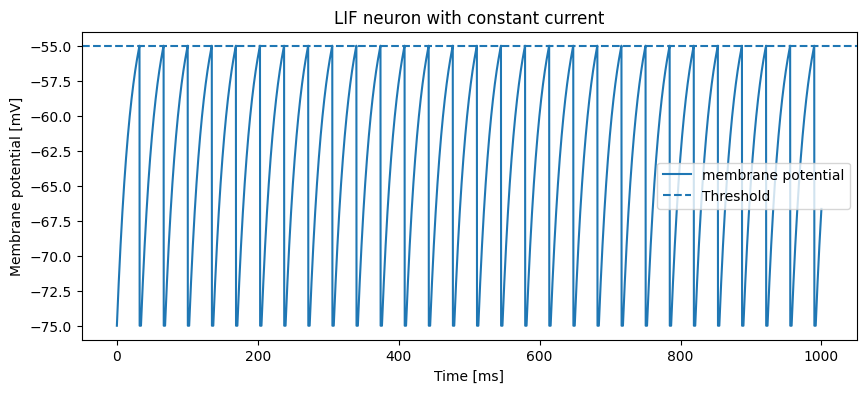

In [5]:
plt.figure(figsize=(10,4))

plt.plot(params['t_steps'], v, label = 'membrane potential')

plt. axhline( params['V_th'], linestyle = '--' ,label = 'Threshold')

plt.xlabel('Time [ms]')
plt.ylabel('Membrane potential [mV]')
plt.title('LIF neuron with constant current')

plt.legend()
plt.show()



### 2.3 Spike-train analysis

The neuron response is described by the firing rate and the inter-spike intervals (s). Firing regularity is measured using the coefficient of variation of the inter-spike intervals:


$$
CV_{\mathrm{s}}=\frac{\sigma_{\mathrm{s}}}{\mu_{\mathrm{s}}}.
$$

A lower $CV_{\mathrm{s}}$ shows a more regular firing, while a higher value indicates the opposite.


In [6]:
def analyse_spikes(spike_times, sim_len):

  # firing rate in Hz
  sim_len_s = sim_len / 1000
  firing_rate = len(spike_times) / sim_len_s

  # Interspike intervals in ms
  s = np.diff(spike_times)

  # CV of s
  if len(s) > 1:
    cv_s = np.std(s) / np.mean(s)
  else:
    cv_s = np.nan

  return firing_rate, s, cv_s

In [7]:
# And to test it
firing_rate, s, cv_s = analyse_spikes(spike_times,params['sim_len'])

print("Firing rate [Hz]:", firing_rate)
print("Mean s [ms]:", np.mean(s))
print("CV_s:", cv_s)

Firing rate [Hz]: 29.0
Mean s [ms]: 34.2
CV_s: 1.1778943450530739e-15


## 3. Gaussian Stochastic Input

### 3.1 Gaussian white-noise current

In the first stage i introduce stochasticity by adding Gaussian noise to the input current:

$$
I(t)=\mu+\sigma\xi(t),
$$

where $\mu$ is the mean input current, $\sigma$ controls the noise amplitude, and $\xi(t)$ is just Gaussian noise.


In [8]:
def gaussian_current (params, mu, sigma, seed = None):
  if seed is not None:
    np.random.seed(seed)

  dt = params['dt']
  t = params['t_steps'].size

  I = mu + sigma * np.random.randn(t) / np.sqrt(dt/1000.)

  return I

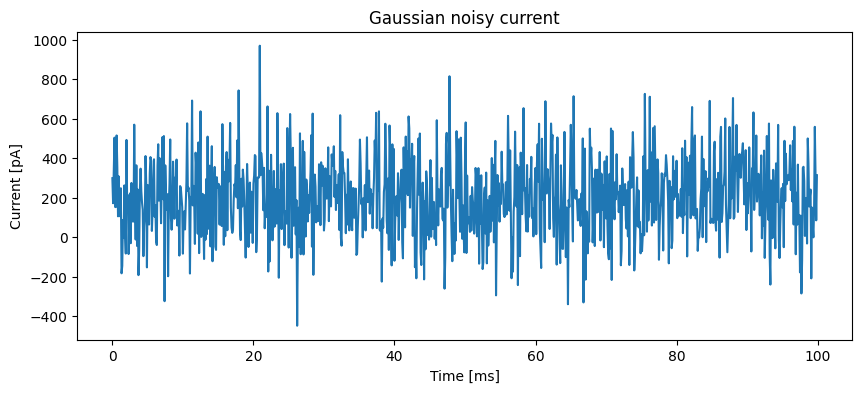

In [9]:
# and a quick test

I_gauss = gaussian_current(params, mu=200, sigma=2, seed=42)

plt.figure(figsize=(10, 4))

plt.plot(params['t_steps'][:1000], I_gauss[:1000])

plt.xlabel('Time [ms]')
plt.ylabel('Current [pA]')
plt.title('Gaussian noisy current')

plt.show()

### 3.2 LIF response to Gaussian input

Let's use the Gaussian current as the input for the LIF neuron, and measure the firing rate and spike train variability

In [10]:
v_gauss, spikes_gauss = run_LIF(params, I_gauss)

Firing rate [Hz]: 12.0
Mean s [ms]: 83.21818181818183
CV_s: 0.32715386005747993


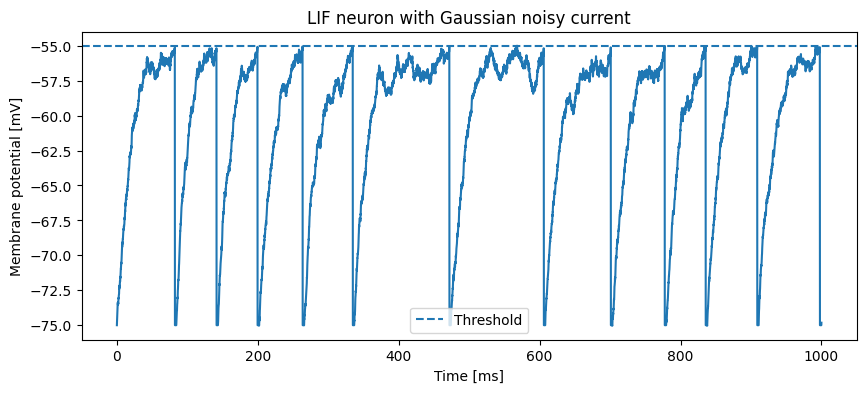

In [11]:
firing_rate_gauss, s_gauss, cv_gauss = analyse_spikes(spikes_gauss, params['sim_len'])

print("Firing rate [Hz]:", firing_rate_gauss)
print("Mean s [ms]:", np.mean(s_gauss))
print("CV_s:", cv_gauss)

plt.figure(figsize=(10, 4))

plt.plot(params['t_steps'], v_gauss)

plt.axhline(params['V_th'], linestyle='--', label='Threshold')

plt.xlabel('Time [ms]')
plt.ylabel('Membrane potential [mV]')
plt.title('LIF neuron with Gaussian noisy current')

plt.legend()
plt.show()

### 3.3 Effect of Gaussian input parameters

In order to check how the stochastic input affects neuron activity, I vary the mean current $\mu$ and the noise amplitude $\sigma$ independently, all while keeping the other fixed.


In [12]:
## First, vary miu, keep sigma fixed

mu_values = np.arange(100,301,20)

sigma_f = 2.0

rates_mu = []
cv_mu = []

for mu in mu_values:
  I_gauss = gaussian_current(params, mu=mu, sigma=sigma_f, seed=42)
  v_gauss, spikes_gauss = run_LIF(params, I_gauss)
  firing_rate_gauss, s_gauss, cv_gauss = analyse_spikes(spikes_gauss, params['sim_len'])

  rates_mu.append(firing_rate_gauss)
  cv_mu.append(cv_gauss)



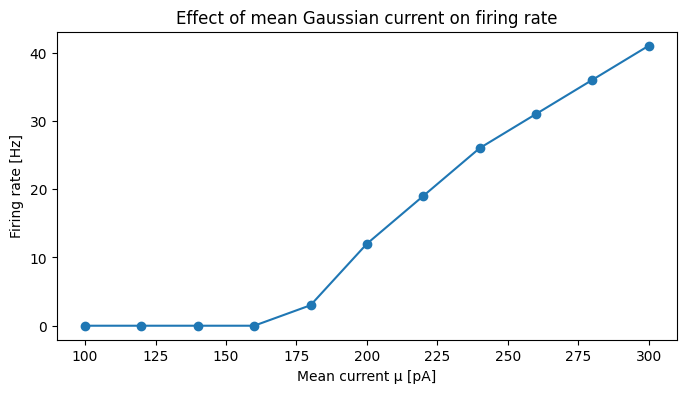

In [13]:
plt.figure(figsize=(8, 4))

plt.plot(mu_values, rates_mu, marker='o')

plt.xlabel('Mean current μ [pA]')
plt.ylabel('Firing rate [Hz]')
plt.title('Effect of mean Gaussian current on firing rate')

plt.show()

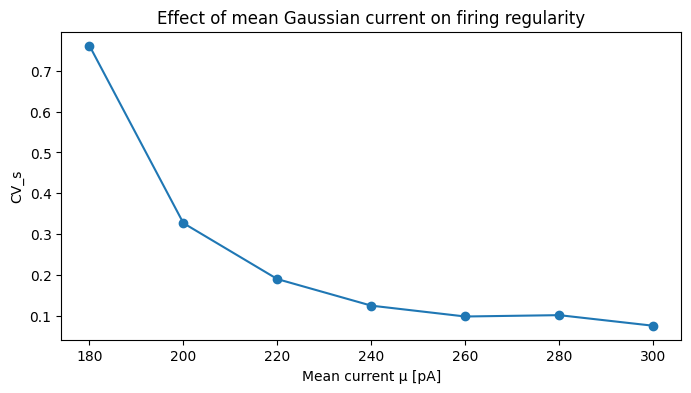

In [14]:
plt.figure(figsize=(8, 4))

plt.plot(mu_values, cv_mu, marker='o')

plt.xlabel('Mean current μ [pA]')
plt.ylabel('CV_s')
plt.title('Effect of mean Gaussian current on firing regularity')

plt.show()

In [15]:
# Now we vary sigma, and keep miu fixed

sigma_values = np.arange(0,5.5, 0.5)

mu_f = 200.

rates_sigma = []
cv_sigma = []

for sigma in sigma_values:
  I_gauss = gaussian_current(params, mu=mu_f, sigma=sigma, seed=42)
  v_gauss, spikes_gauss = run_LIF(params, I_gauss)
  firing_rate_gauss, s_gauss, cv_gauss = analyse_spikes(spikes_gauss, params['sim_len'])

  rates_sigma.append(firing_rate_gauss)
  cv_sigma.append(cv_gauss)


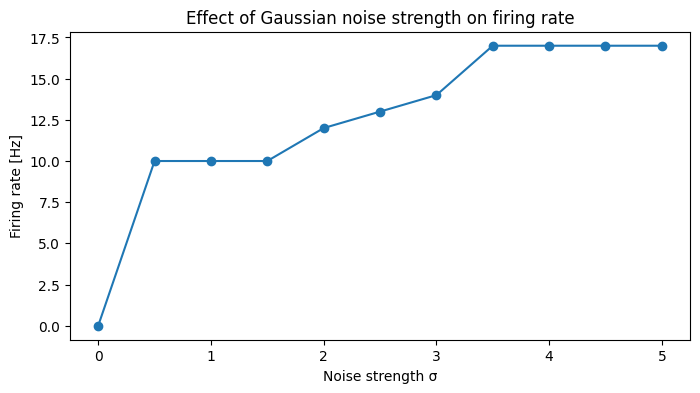

In [16]:
plt.figure(figsize=(8, 4))

plt.plot(sigma_values, rates_sigma, marker='o')

plt.xlabel('Noise strength σ')
plt.ylabel('Firing rate [Hz]')
plt.title('Effect of Gaussian noise strength on firing rate')

plt.show()

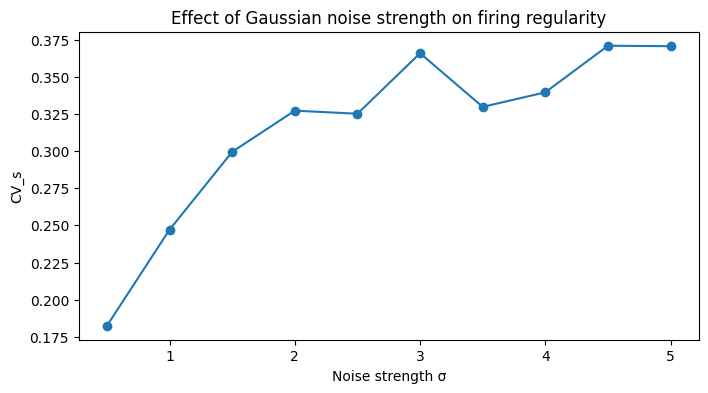

In [17]:
plt.figure(figsize=(8, 4))

plt.plot(sigma_values, cv_sigma, marker='o')

plt.xlabel('Noise strength σ')
plt.ylabel('CV_s')
plt.title('Effect of Gaussian noise strength on firing regularity')

plt.show()

## Our Gaussian baseline is complete. We can now move on to working on the Poisson pipeline

## 4. Poisson Synaptic Input

### 4.1 Presynaptic Poisson spike trains

The input is modeled as a population of presynaptic neurons, whose spikes are generated by the following spike generator. For a small time step $\Delta t$, the probability of a spike is approximately

$$
P(\mathrm{spike})=\lambda \Delta t,
$$

where $\lambda$ is the presynaptic firing rate.


In [18]:
# Let's create a poisson spike generator

def Poisson_generator(params, rate, N):
  dt, t_steps = params['dt'], params['t_steps']
  t = t_steps.size

  rand_ = np.random.rand(N,t)

  spike_train = 1. * (rand_ < rate * (dt / 1000.))

  return spike_train

In [19]:
poisson_input = Poisson_generator(params, rate=10, N=100)
print(poisson_input.shape)

(100, 10000)


### 4.2 Synaptic activation

Each neuron gets assigned a synaptic activation variable $P_j(t)$. After each of the spikes, the activation is set to all the way to 1 and then decays exponentially with synaptic time constant $\tau_s$:


$$P_j(t+\Delta t)=P_j(t)e^{-\Delta t/\tau_s}.$$


In [20]:
def synaptic_activation(params, spike_trains, tau_s = 5.0):
  dt = params['dt']

  N, t = spike_trains.shape
  P = np.zeros((N,t))

  decay = np.exp(-dt/tau_s)

  for i in range (t-1):
    # synapric activation decay
    P[:, i+1] = P[:,i] * decay
    # synapses that recieve a spike become active
    spiking_neurons = spike_trains[:,i] == 1

    P [spiking_neurons, i+1] = 1.0
  return P

In [21]:
P = synaptic_activation(params, poisson_input, tau_s=5.0)
print(P.shape)


(100, 10000)


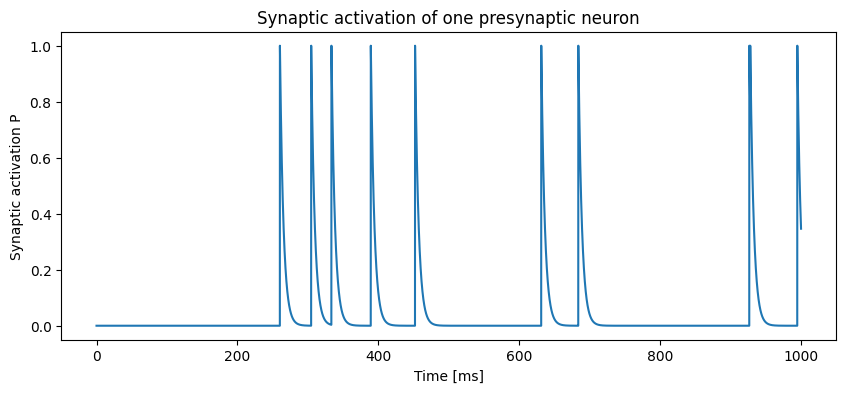

In [22]:
plt.figure(figsize=(10, 4))
plt.plot(params['t_steps'], P[0])
plt.xlabel('Time [ms]')
plt.ylabel('Synaptic activation P')
plt.title('Synaptic activation of one presynaptic neuron')
plt.show()

### 4.3 Synaptic conductance

Converting synaptic activation into conductance:
$$g_j(t)=\bar{g}\,P_j(t),$$


The total conductance is obtained by summing over all the neurons

In [23]:
g_bar = 1 # arbitrary for now, but a sweep is performed later in the project

(10000,)


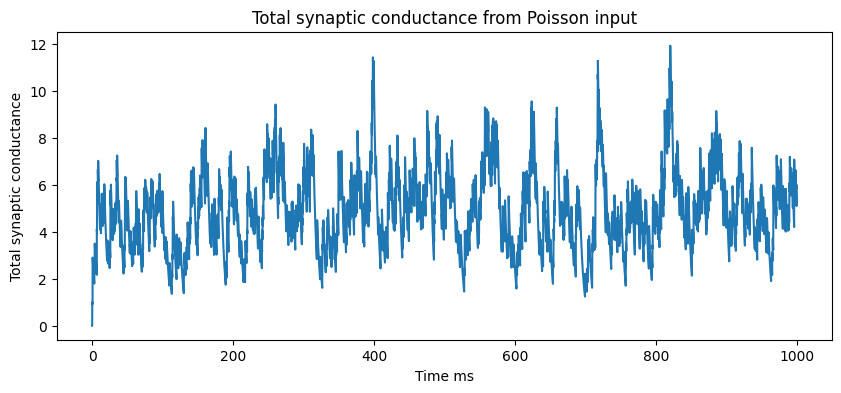

In [24]:
g_syn = g_bar * P
g_total = np.sum(g_syn, axis=0)
print(g_total.shape)
plt.figure(figsize=(10, 4))
plt.plot(params['t_steps'], g_total)
plt.xlabel('Time ms')
plt.ylabel('Total synaptic conductance')
plt.title('Total synaptic conductance from Poisson input')
plt.show()

### 4.4 LIF neuron driven by synaptic conductance

The synaptic current is dependent on both the conductance and the membrane potential:

$$I_{\mathrm{syn}}(t)=g_{\mathrm{syn}}(t)\left(E_s-V(t)\right)$$

Now i extended the LIF equation to also include the synaptic term

In [25]:
def run_LIF_synaptic(params,g_total,E_s=0.0,I_ext=0.0):

    # Set params
    V_th, V_reset, V_init, g_L, tau_m, E_L = params['V_th'], params['V_reset'], params['V_init'],params['g_L'], params['tau_m'], params['E_L']
    tref = params['tref']
    dt = params['dt']
    t_steps = params['t_steps']
    t = t_steps.size

    # initialize the membrane voltage
    v = np.zeros(t)
    v[0] = V_init

    # and convert external current to array if it is a constant
    I_ext = I_ext * np.ones(t)

    # Refractory counter
    tr = 0

    rec_spikes = []

    for i in range(t - 1):
        if tr > 0:
            v[i] = V_reset
            tr = tr - 1
        elif v[i] >= V_th:
            rec_spikes.append(i)
            v[i] = V_reset
            tr = tref/dt

        # Conductance-based synaptic contribution
        synaptic_term = -(g_total[i] / g_L) * (v[i] - E_s)

        # LIF membrane equation we are working with
        dv = (-(v[i] - E_L) + synaptic_term + I_ext[i] / g_L) * (dt / tau_m)

        # Update the membrane voltage
        v[i + 1] = v[i] + dv

    # Convert spike indices to milliseconds
    rec_spikes = np.array(rec_spikes) * dt

    return v, rec_spikes

In [26]:
v_syn, spikes_syn = run_LIF_synaptic(params, g_total, E_s=0.0, I_ext=0.0)

Firing rate [Hz]: 39.0
Mean s [ms]: 25.360526315789475
CV_s: 0.36001447213721427


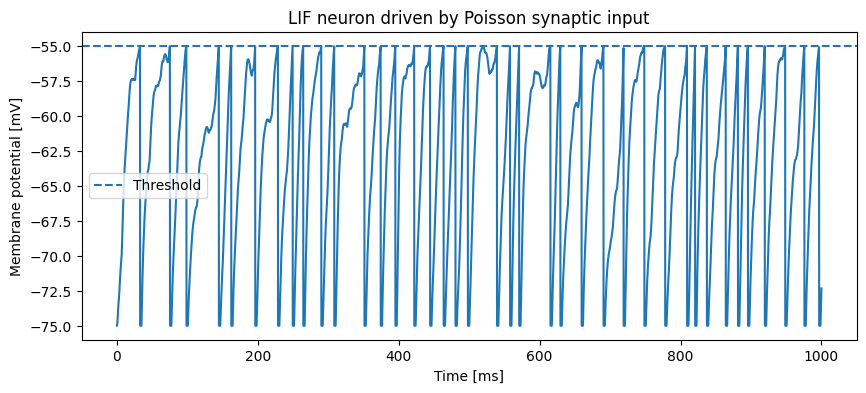

In [27]:
firing_rate_syn, s_syn, cv_syn = analyse_spikes(spikes_syn, params['sim_len'])

print("Firing rate [Hz]:", firing_rate_syn)
print("Mean s [ms]:", np.mean(s_syn) if len(s_syn) > 0 else np.nan)
print("CV_s:", cv_syn)
plt.figure(figsize=(10, 4))
plt.plot(params['t_steps'], v_syn)
plt.axhline(params['V_th'], linestyle='--', label='Threshold')
plt.xlabel('Time [ms]')
plt.ylabel('Membrane potential [mV]')
plt.title('LIF neuron driven by Poisson synaptic input')
plt.legend()
plt.show()

### 4.5 Effect of synaptic parameters

firstly, let's vary the maximum synaptic conductance $\bar g$ in order to study its effect on the postsynaptic firing rate and firing variability.


In [28]:
gbar_values = np.arange(0.1, 1.6, 0.1)

rates_gbar = []
cv_gbar = []

for g_bar in gbar_values:

    g_syn = g_bar * P
    g_total = np.sum(g_syn, axis=0)

    v_syn, spikes_syn = run_LIF_synaptic(params, g_total, E_s=0.0, I_ext=0.0)

    firing_rate_syn, s_syn, cv_syn = analyse_spikes(spikes_syn, params['sim_len'])

    rates_gbar.append(firing_rate_syn)
    cv_gbar.append(cv_syn)

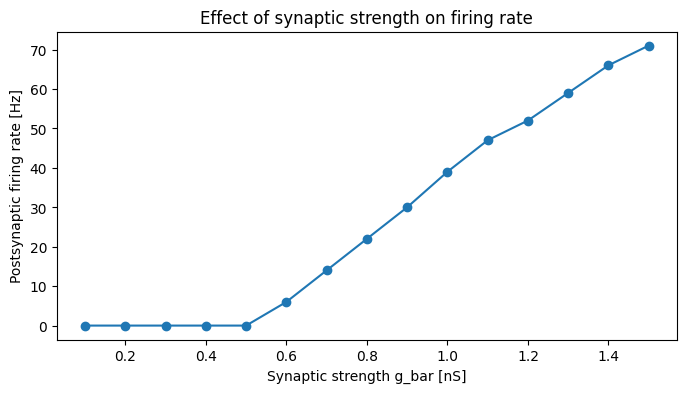

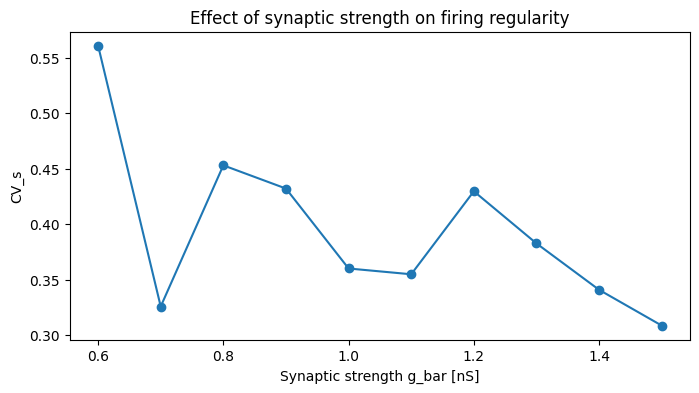

In [29]:
plt.figure(figsize=(8, 4))
plt.plot(gbar_values, rates_gbar, marker='o')
plt.xlabel('Synaptic strength g_bar [nS]')
plt.ylabel('Postsynaptic firing rate [Hz]')
plt.title('Effect of synaptic strength on firing rate')
plt.show()
plt.figure(figsize=(8, 4))
plt.plot(gbar_values, cv_gbar, marker='o')
plt.xlabel('Synaptic strength g_bar [nS]')
plt.ylabel('CV_s')
plt.title('Effect of synaptic strength on firing regularity')
plt.show()

The Poisson firing rate $\lambda$ is now varied while the other synaptic params are kept fixed.


In [30]:
rate_values = [1, 2, 5, 10, 15, 20, 30, 40, 50]

rates_post = []
cv_post = []

In [31]:
for rate in rate_values:

    poisson_input = Poisson_generator(params, rate=rate, N=100)

    P = synaptic_activation(params, poisson_input, tau_s=5.0)

    g_syn = 1.0 * P
    g_total = np.sum(g_syn, axis=0)

    v_syn, spikes_syn = run_LIF_synaptic(params, g_total, E_s=0.0, I_ext=0.0)
    firing_rate_syn, s_syn, cv_syn = analyse_spikes(spikes_syn, params['sim_len'])
    rates_post.append(firing_rate_syn)
    cv_post.append(cv_syn)

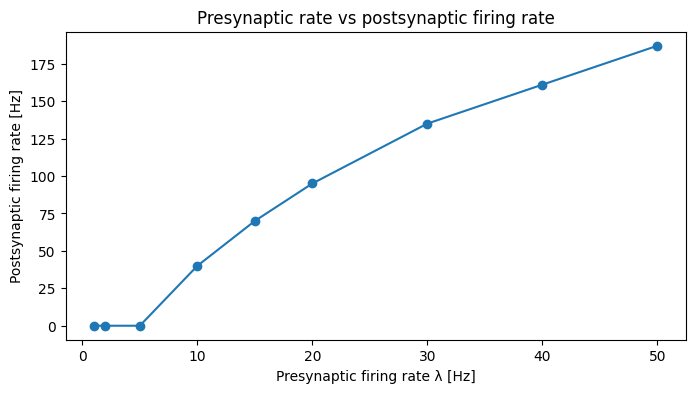

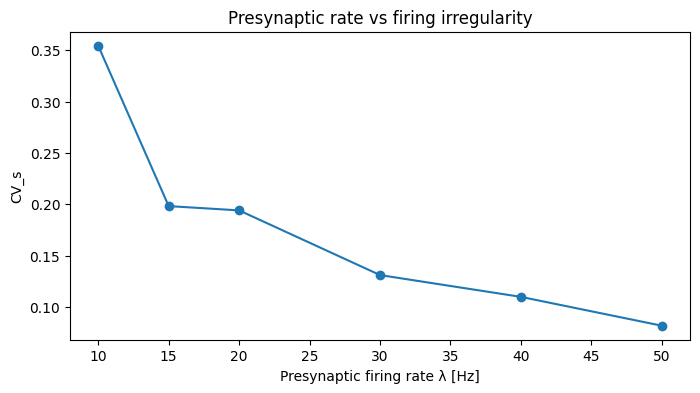

In [32]:
plt.figure(figsize=(8, 4))
plt.plot(rate_values, rates_post, marker='o')
plt.xlabel('Presynaptic firing rate λ [Hz]')
plt.ylabel('Postsynaptic firing rate [Hz]')
plt.title('Presynaptic rate vs postsynaptic firing rate')
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(rate_values, cv_post, marker='o')
plt.xlabel('Presynaptic firing rate λ [Hz]')
plt.ylabel('CV_s')
plt.title('Presynaptic rate vs firing irregularity')
plt.show()

## 5. Comparison of Gaussian and Poisson Input

To compare the two input models fairly, we should choose parameters in such a way that they produce approximately similar postsynaptic firing rates. Their firing rates and $CV_{\mathrm{s}}$ values can then be compared.


In [33]:
poisson_input_ref = Poisson_generator(params, rate=10, N=100)
P_ref = synaptic_activation(params, poisson_input_ref, tau_s=5.0)
g_syn_ref = 1.0 * P_ref
g_total_ref = np.sum(g_syn_ref, axis=0)

v_poisson_ref, spikes_poisson_ref = run_LIF_synaptic(params, g_total_ref, E_s=0.0, I_ext=0.0)

rate_poisson_ref, s_poisson_ref, cv_poisson_ref = analyse_spikes(spikes_poisson_ref, params['sim_len'])

print("Poisson firing rate:", rate_poisson_ref)
print("Poisson CV_s:", cv_poisson_ref)

Poisson firing rate: 36.0
Poisson CV_s: 0.30246533706707535


In [34]:
mu_match_values = np.arange(200, 401, 10)

gauss_match_rates = []
gauss_match_cv = []

for mu in mu_match_values:

    I_gauss = gaussian_current(params, mu=mu, sigma=2.0, seed=42)

    v_gauss, spikes_gauss = run_LIF(params, I_gauss)

    rate_gauss, s_gauss, cv_gauss = analyse_spikes(spikes_gauss, params['sim_len'])

    gauss_match_rates.append(rate_gauss)
    gauss_match_cv.append(cv_gauss)

In [35]:
for mu, rate, cv in zip(mu_match_values, gauss_match_rates, gauss_match_cv):
    print("mu =", mu, "rate =", rate, "CV =", cv)

mu = 200 rate = 12.0 CV = 0.32715386005747993
mu = 210 rate = 17.0 CV = 0.22963448052564492
mu = 220 rate = 19.0 CV = 0.19031414017535173
mu = 230 rate = 23.0 CV = 0.13145726993771562
mu = 240 rate = 26.0 CV = 0.12534776051193466
mu = 250 rate = 28.0 CV = 0.11421408250285629
mu = 260 rate = 31.0 CV = 0.09880232407719768
mu = 270 rate = 34.0 CV = 0.0835874617417817
mu = 280 rate = 36.0 CV = 0.1020900441337596
mu = 290 rate = 39.0 CV = 0.07550181158090336
mu = 300 rate = 41.0 CV = 0.07622888898557109
mu = 310 rate = 44.0 CV = 0.07017079578563086
mu = 320 rate = 46.0 CV = 0.06128093210885292
mu = 330 rate = 48.0 CV = 0.067856645033699
mu = 340 rate = 50.0 CV = 0.0682328147563822
mu = 350 rate = 52.0 CV = 0.07850847119704947
mu = 360 rate = 54.0 CV = 0.059135635251816684
mu = 370 rate = 56.0 CV = 0.056556159258290536
mu = 380 rate = 58.0 CV = 0.058639575707689046
mu = 390 rate = 60.0 CV = 0.05492871725195856
mu = 400 rate = 62.0 CV = 0.05335046854127182


 Here the matching frequency of 36 Hz is: mu = 280 rate = 36.0 CV = 0.1020900441337596


In [36]:
I_gauss_match = gaussian_current(params, mu=280, sigma=2.0, seed=42)
v_gauss_match, spikes_gauss_match = run_LIF(params, I_gauss_match)
rate_gauss_match, s_gauss_match, cv_gauss_match = analyse_spikes(spikes_gauss_match, params['sim_len'])

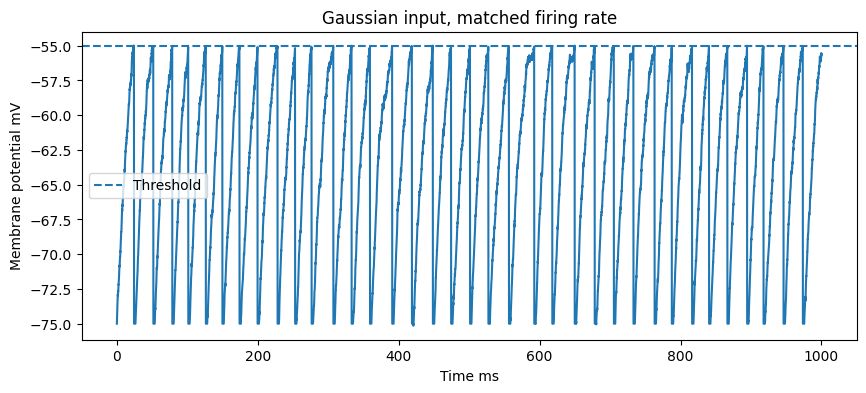

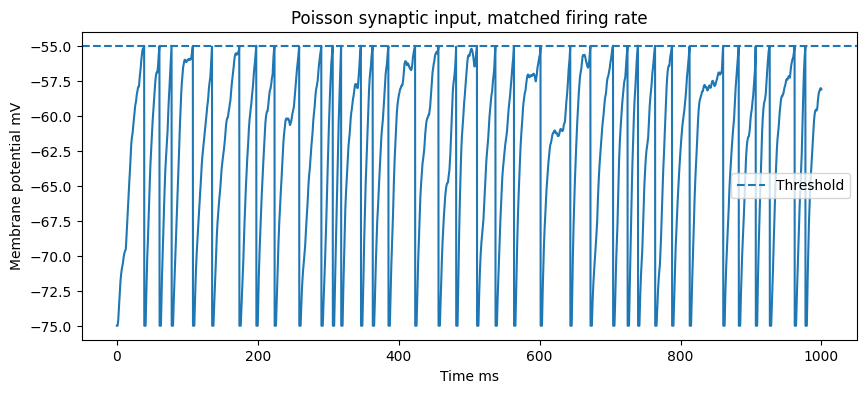

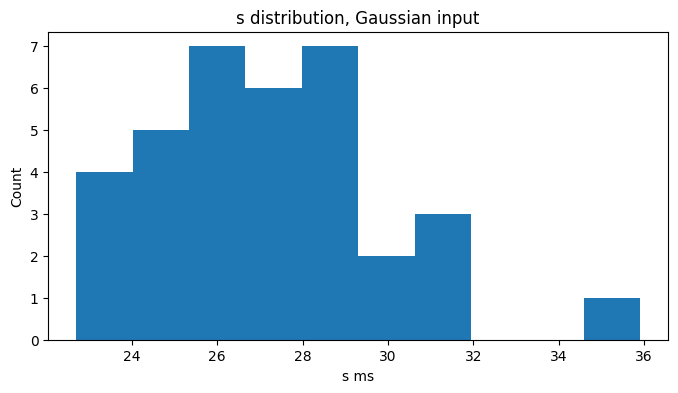

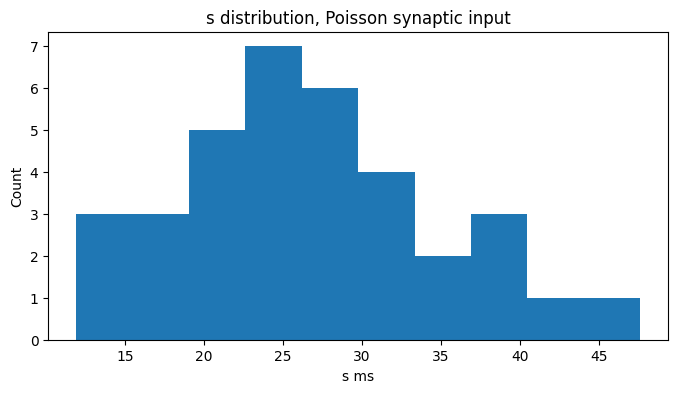

In [37]:
plt.figure(figsize=(10, 4))
plt.plot(params['t_steps'], v_gauss_match)
plt.axhline(params['V_th'], linestyle='--', label='Threshold')
plt.xlabel('Time ms')
plt.ylabel('Membrane potential mV')
plt.title('Gaussian input, matched firing rate')
plt.legend()
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(params['t_steps'], v_poisson_ref)
plt.axhline(params['V_th'], linestyle='--', label='Threshold')
plt.xlabel('Time ms')
plt.ylabel('Membrane potential mV')
plt.title('Poisson synaptic input, matched firing rate')
plt.legend()
plt.show()

plt.figure(figsize=(8, 4))
plt.hist(s_gauss_match, bins=10)
plt.xlabel('s ms')
plt.ylabel('Count')
plt.title('s distribution, Gaussian input')
plt.show()

plt.figure(figsize=(8, 4))
plt.hist(s_poisson_ref, bins=10)
plt.xlabel('s ms')
plt.ylabel('Count')
plt.title('s distribution, Poisson synaptic input')
plt.show()

## 6. Excitatory and Inhibitory Poisson Populations

### 6.1 The E/I conductance model

 By separating the presynaptic population into excitatory and inhibitory neurons, I can extend the Poisson model. Their contributions are described using different reversal potentials:

$$
I_E=g_E(E_E-V),
\qquad
I_I=g_I(E_I-V).
$$

Must include both terms in the LIF membrane equation.


In [38]:
def run_LIF_EI(params, g_E, g_I, E_E=0.0, E_I=-80.0, I_ext=0.0):

    V_th, V_reset, V_init, g_L, tau_m, E_L = params['V_th'], params['V_reset'], params['V_init'],params['g_L'], params['tau_m'], params['E_L']
    tref = params['tref']
    dt = params['dt']
    t_steps = params['t_steps']
    t = t_steps.size

    v = np.zeros(t)
    v[0] = V_init
    I_ext = I_ext * np.ones(t)

    tr = 0
    rec_spikes = []

    for i in range(t - 1):
        if tr > 0:
            v[i] = V_reset
            tr = tr - 1
        elif v[i] >= V_th:
            rec_spikes.append(i)
            v[i] = V_reset
            tr = tref /dt

        excitatory_term = -(g_E[i] / g_L) * (v[i] - E_E)
        inhibitory_term = -(g_I[i] / g_L) * (v[i] - E_I)

        dv = (-(v[i] - E_L) + excitatory_term + inhibitory_term + I_ext[i] / g_L) * (dt / tau_m)

        v[i + 1] = v[i] + dv

    rec_spikes = np.array(rec_spikes) * dt

    return v, rec_spikes

Just for an initial simulation we can use 80 excitatory and 20 inhibitory presynaptic neurons to illustrate the combined E/I input.


In [39]:
poisson_E = Poisson_generator(params, rate=10, N=80)
poisson_I = Poisson_generator(params, rate=10, N=20)

P_E = synaptic_activation(params, poisson_E, tau_s=5.0)
P_I = synaptic_activation(params, poisson_I, tau_s=5.0)

g_bar_E = 1.0
g_bar_I = 1.0
g_E = np.sum(g_bar_E * P_E, axis=0)
g_I = np.sum(g_bar_I * P_I, axis=0)

v_EI, spikes_EI = run_LIF_EI(params, g_E, g_I, E_E = 0.0, E_I = -80.0, I_ext = 0.0)

Firing rate [Hz]: 17.0
Mean s [ms]: 56.15625
CV_s: 0.3809724097669754


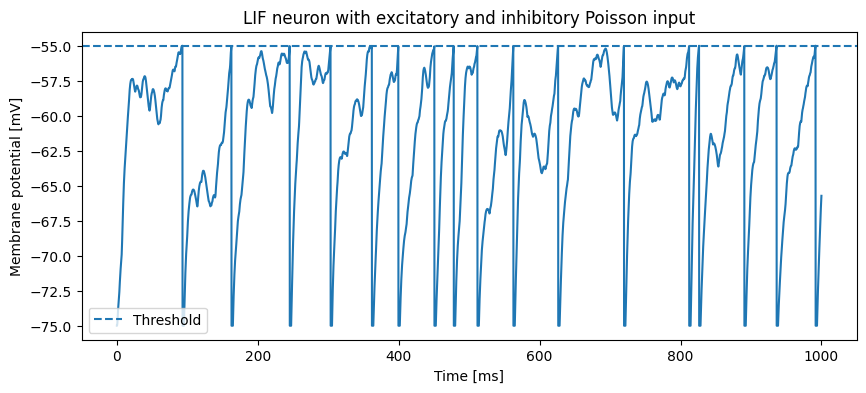

In [40]:
rate_EI, s_EI, cv_EI = analyse_spikes(spikes_EI, params['sim_len'])

print("Firing rate [Hz]:", rate_EI)
print("Mean s [ms]:", np.mean(s_EI) if len(s_EI) > 0 else np.nan)
print("CV_s:", cv_EI)
plt.figure(figsize=(10, 4))
plt.plot(params['t_steps'], v_EI)
plt.axhline(params['V_th'], linestyle='--', label='Threshold')
plt.xlabel('Time [ms]')
plt.ylabel('Membrane potential [mV]')
plt.title('LIF neuron with excitatory and inhibitory Poisson input')
plt.legend()
plt.show()

### 6.2 Effect of E/I population composition

The total population is kept the same. Meanwhile the proportion of excitatory and inhibitory neurons is varied.


In [41]:
EI_conditions = [(100, 0), (80, 20), (60, 40), (50, 50), (40, 60), (20, 80)]

rates_EI = []
cv_EI = []

In [42]:
for N_E, N_I in EI_conditions:

    if N_E > 0:
        poisson_E=Poisson_generator(params, rate=10, N=N_E)
        P_E=synaptic_activation(params, poisson_E, tau_s=5.0)
        g_E=np.sum(1.0 * P_E, axis=0)
    else:
        g_E = np.zeros(params['t_steps'].size)


    if N_I > 0:
        poisson_I=Poisson_generator(params, rate=10, N=N_I)
        P_I=synaptic_activation(params, poisson_I, tau_s=5.0)
        g_I=np.sum(1.0 * P_I, axis=0)
    else:
        g_I = np.zeros(params['t_steps'].size)

    v_EI, spikes_EI = run_LIF_EI(params, g_E, g_I, E_E=0.0, E_I=-80.0, I_ext=0.0)

    rate_EI, s_EI, cv_value = analyse_spikes(spikes_EI, params['sim_len'])

    rates_EI.append(rate_EI)
    cv_EI.append(cv_value)

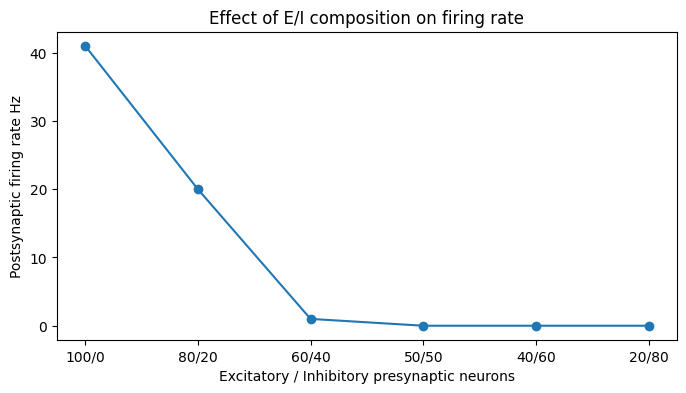

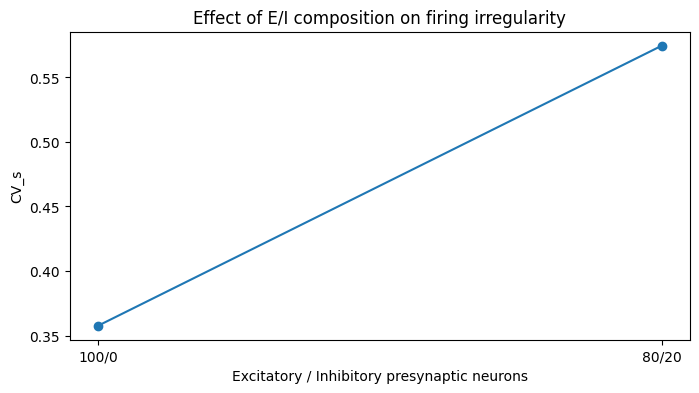

In [43]:
labels_EI = [f"{E}/{I}" for E, I in EI_conditions]
plt.figure(figsize=(8, 4))
plt.plot(labels_EI, rates_EI, marker='o')
plt.xlabel('Excitatory / Inhibitory presynaptic neurons')
plt.ylabel('Postsynaptic firing rate Hz')
plt.title('Effect of E/I composition on firing rate')
plt.show()


plt.figure(figsize=(8, 4))
plt.plot(labels_EI, cv_EI, marker='o')
plt.xlabel('Excitatory / Inhibitory presynaptic neurons')
plt.ylabel('CV_s')
plt.title('Effect of E/I composition on firing irregularity')
plt.show()

### 6.3 Repeated stochastic trials

Because the Poisson inputs are random, each E/I condition is repeated over multiple realizations. We should take a look at the mean and standard deviation of the firing rate and $CV_{\mathrm{s}}$.


In [44]:
EI_conditions = [(100, 0), (80, 20), (60, 40), (50, 50), (40, 60), (20, 80)]

n_trials = 20

mean_rates_EI = []
std_rates_EI = []
mean_cv_EI = []
std_cv_EI = []

for N_E, N_I in EI_conditions:

    trial_rates = []
    trial_cv = []

    for trial in range(n_trials):

        if N_E > 0:
            poisson_E= Poisson_generator(params, rate= 10, N=N_E)
            P_E=synaptic_activation(params, poisson_E, tau_s=5.0)
            g_E=np.sum(1.0 * P_E, axis=0)
        else:
            g_E=np.zeros(params['t_steps'].size)


        if N_I > 0:
            poisson_I=Poisson_generator(params, rate=10, N=N_I)
            P_I=synaptic_activation(params, poisson_I, tau_s=5.0)
            g_I=np.sum(1.0 * P_I, axis=0)
        else:
            g_I=np.zeros(params['t_steps'].size)

        v_EI, spikes_EI=run_LIF_EI(params, g_E, g_I, E_E=0.0, E_I=-80.0, I_ext=0.0)

        rate_EI, s_EI, cv_value=analyse_spikes(spikes_EI, params['sim_len'])

        trial_rates.append(rate_EI)

        if not np.isnan(cv_value):
            trial_cv.append(cv_value)

    mean_rates_EI.append(np.mean(trial_rates))
    std_rates_EI.append(np.std(trial_rates))

    if len(trial_cv) > 0:
        mean_cv_EI.append(np.mean(trial_cv))
        std_cv_EI.append(np.std(trial_cv))
    else:
        mean_cv_EI.append(np.nan)
        std_cv_EI.append(np.nan)

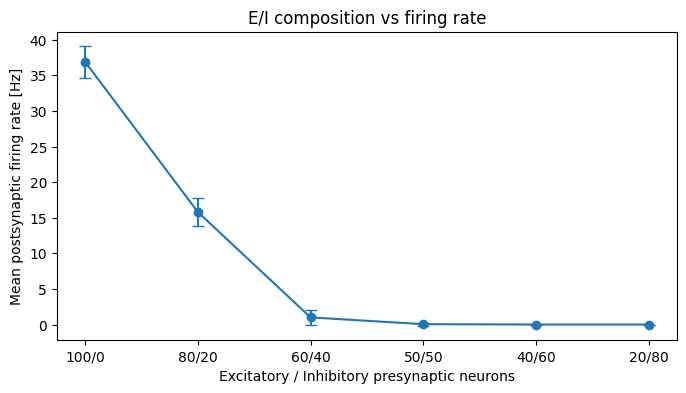

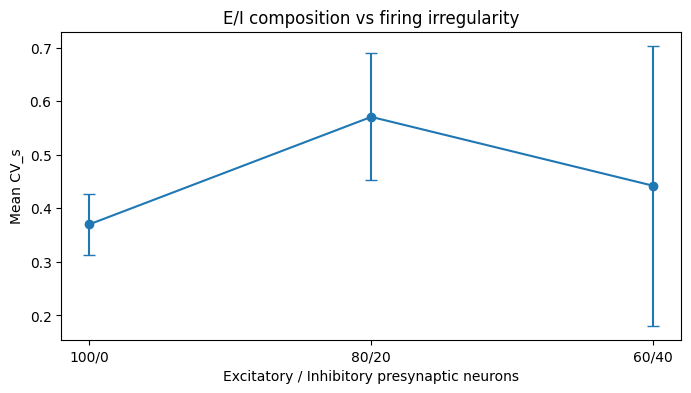

In [45]:
labels_EI = [f"{E}/{I}" for E, I in EI_conditions]

plt.figure(figsize=(8, 4))
plt.errorbar(labels_EI, mean_rates_EI, yerr=std_rates_EI, marker='o', capsize=4)
plt.xlabel('Excitatory / Inhibitory presynaptic neurons')
plt.ylabel('Mean postsynaptic firing rate [Hz]')
plt.title('E/I composition vs firing rate')
plt.show()

plt.figure(figsize=(8, 4))
plt.errorbar(labels_EI, mean_cv_EI, yerr=std_cv_EI, marker='o', capsize=4)
plt.xlabel('Excitatory / Inhibitory presynaptic neurons')
plt.ylabel('Mean CV_s')
plt.title('E/I composition vs firing irregularity')
plt.show()

The presynaptic firing-rate sweep is also repeated across multiple stochastic realizations to obtain some more robust estimates.


In [46]:
rate_values = [1, 2, 5, 10, 15, 20, 30, 40, 50]

n_trials = 20

mean_rates_pre = []
std_rates_pre = []
mean_cv_pre = []
std_cv_pre = []

for rate in rate_values:

    trial_rates = []
    trial_cv = []

    for trial in range(n_trials):

        poisson_input = Poisson_generator(params, rate=rate, N=100)
        P = synaptic_activation(params, poisson_input, tau_s=5.0)

        g_syn = 1.0 * P
        g_total = np.sum(g_syn, axis=0)

        v_syn, spikes_syn = run_LIF_synaptic(params, g_total, E_s=0.0, I_ext=0.0)
        firing_rate_syn, s_syn, cv_syn = analyse_spikes(spikes_syn, params['sim_len'])
        trial_rates.append(firing_rate_syn)

        if not np.isnan(cv_syn):
            trial_cv.append(cv_syn)

    mean_rates_pre.append(np.mean(trial_rates))
    std_rates_pre.append(np.std(trial_rates))

    if len(trial_cv) > 0:
        mean_cv_pre.append(np.mean(trial_cv))
        std_cv_pre.append(np.std(trial_cv))
    else:
        mean_cv_pre.append(np.nan)
        std_cv_pre.append(np.nan)

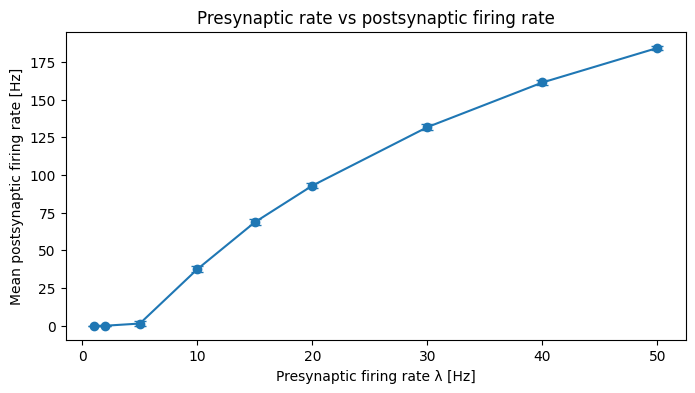

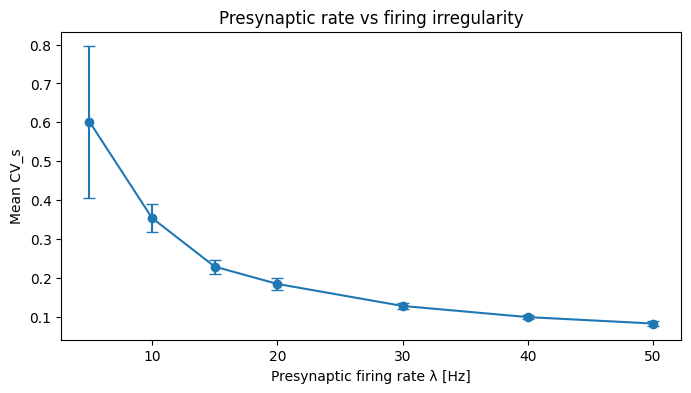

In [47]:
plt.figure(figsize=(8, 4))
plt.errorbar(rate_values, mean_rates_pre, yerr=std_rates_pre, marker='o', capsize=4)
plt.xlabel('Presynaptic firing rate λ [Hz]')
plt.ylabel('Mean postsynaptic firing rate [Hz]')
plt.title('Presynaptic rate vs postsynaptic firing rate')
plt.show()
plt.figure(figsize=(8, 4))
plt.errorbar(rate_values, mean_cv_pre, yerr=std_cv_pre, marker='o', capsize=4)
plt.xlabel('Presynaptic firing rate λ [Hz]')
plt.ylabel('Mean CV_s')
plt.title('Presynaptic rate vs firing irregularity')
plt.show()

### 6.4 Repeated Gaussian–Poisson comparison

Lastly, the matched Gaussian and Poisson conditions are repeated over more random realizations to compare their average firing rates and firing variability.


In [48]:
n_trials = 10

rates_poisson_trials = []
cv_poisson_trials = []
rates_gaussian_trials = []
cv_gaussian_trials = []

for trial in range(n_trials):

    # Poisson synaptic input
    poisson_input = Poisson_generator(params, rate=10, N=100)
    P = synaptic_activation(params, poisson_input, tau_s=5.0)

    g_syn=1.0 * P
    g_total=  np.sum(g_syn, axis=0)

    v_poisson, spikes_poisson=run_LIF_synaptic(params, g_total, E_s=0.0, I_ext=0.0)
    rate_poisson, s_poisson, cv_poisson=analyse_spikes(spikes_poisson, params['sim_len'])
    rates_poisson_trials.append(rate_poisson)

    if not np.isnan(cv_poisson):
        cv_poisson_trials.append(cv_poisson)

    # Gaussian noisy input
    I_gauss=gaussian_current(params, mu=280, sigma=2.0)

    v_gauss,spikes_gauss=run_LIF(params, I_gauss)

    rate_gauss,s_gauss,cv_gauss=analyse_spikes(spikes_gauss, params['sim_len'])

    rates_gaussian_trials.append(rate_gauss)

    if not np.isnan(cv_gauss):
        cv_gaussian_trials.append(cv_gauss)

In [49]:
print("Poisson mean firing rate:", np.mean(rates_poisson_trials))
print("Poisson firing-rate std:", np.std(rates_poisson_trials))
print("Poisson mean CV:", np.mean(cv_poisson_trials))
print()

print("Gaussian mean firing rate:", np.mean(rates_gaussian_trials))
print("Gaussian firing-rate std:", np.std(rates_gaussian_trials))
print("Gaussian mean CV:", np.mean(cv_gaussian_trials))

Poisson mean firing rate: 37.6
Poisson firing-rate std: 2.615339366124404
Poisson mean CV: 0.3850743353502154

Gaussian mean firing rate: 36.6
Gaussian firing-rate std: 0.66332495807108
Gaussian mean CV: 0.08655291508881512


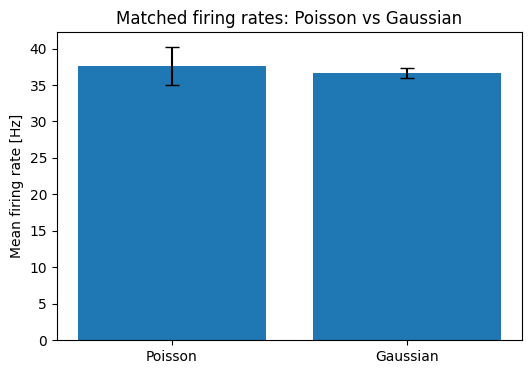

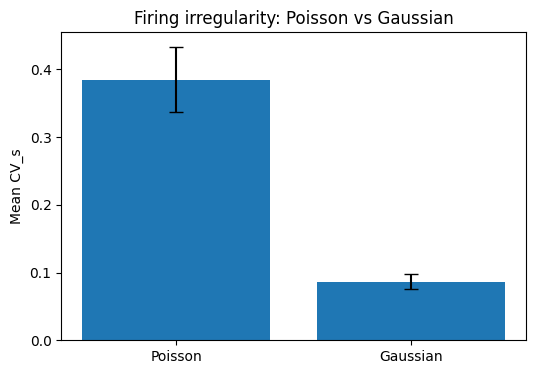

In [50]:
labels = ['Poisson', 'Gaussian']
mean_rates = [np.mean(rates_poisson_trials), np.mean(rates_gaussian_trials)]
std_rates = [np.std(rates_poisson_trials), np.std(rates_gaussian_trials)]

plt.figure(figsize=(6, 4))
plt.bar(labels, mean_rates, yerr=std_rates, capsize=5)
plt.ylabel('Mean firing rate [Hz]')
plt.title('Matched firing rates: Poisson vs Gaussian')
plt.show()
mean_cv = [np.mean(cv_poisson_trials), np.mean(cv_gaussian_trials)]
std_cv = [np.std(cv_poisson_trials), np.std(cv_gaussian_trials)]

plt.figure(figsize=(6, 4))
plt.bar(labels, mean_cv, yerr=std_cv, capsize=5)
plt.ylabel('Mean CV_s')
plt.title('Firing irregularity: Poisson vs Gaussian')
plt.show()

## 7. Conclusion

Our tests show how both the statistics and the structure of the stochastic input influnece the LIF neuron firing. While they can have a similar mean, the Gaussian current noise and the Poisson synaptic input can vastly differ in spike time variability. The balance between excitation and inhibation strongly affects the neuronal response
